# Sentiment Analysis Script

**Author:** Alex Alkhatib

This notebook loads a tweet dataset (`dataset.csv`), detects the language of each text, keeps only English rows, computes a polarity-based sentiment with TextBlob, then displays a word cloud and a bar chart of the sentiment distribution.

## Importing Libraries

In [1]:
!pip install pandas wordcloud matplotlib langdetect sumy textblob seaborn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   --------- ------------------------------ 0.3/1.1 MB ? eta -:--:--
   ------------------- -------------------- 0.5/1.1 MB 989.2 kB/s eta 0:00:01
   ----------------------------- ---------- 0.8/1.1 MB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 1.1/1.1 MB 1.2 MB/s  0:00:00
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------- ----------------------- 262.1/625.0 kB ? eta -:--:--
   ------------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
from langdetect import detect
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer
from textblob import TextBlob
import seaborn as sns

## Reading the CSV File

In [3]:
# Reading the CSV File
df = pd.read_csv('dataset.csv')

## Detecting Languages

In [4]:
# Quick check on a single text
text = df['Text'][1]
lang = detect(text)

In [5]:
# Creating a function to detect languages
def det(text):
    try:
        lang = detect(text)
    except:
        lang = 'Other'
    return lang

In [6]:
df['Lang'] = df['Text'].apply(det)

## Cleaning Text

In [7]:
df = df.loc[df['Lang'] == 'en']
df = df.reset_index(drop=True)

# Cleaning some data
df['Text'] = df['Text'].str.replace('https', '')
df['Text'] = df['Text'].str.replace('http', '')
df['Text'] = df['Text'].str.replace('t.co', '')

## Sentiment Analysis

In [8]:
# Developing a sentiment function
def get_sentiment(text):
    sentiment = TextBlob(text).sentiment.polarity
    if sentiment > 0:
        return 'Positive'
    elif sentiment < 0:
        return 'Negative'
    else:
        return 'Neutral'

In [9]:
# Add the function to our dataframe
df['Sentiment'] = df['Text'].apply(get_sentiment)

## Generating a Word Cloud

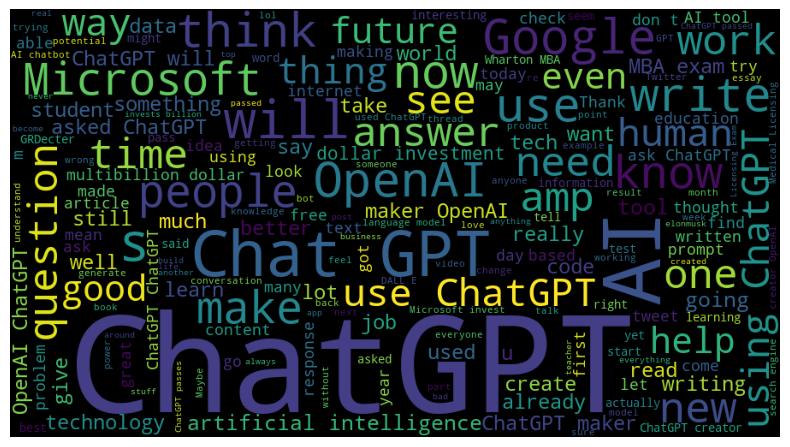

In [10]:
comment_words = ''
stopwords = set(STOPWORDS)

for val in df.Text:
    val = str(val)
    tokens = val.split()
    comment_words = comment_words + " ".join(tokens)+ " "

wordcloud = WordCloud(width=900, height=500, background_color = 'black', 
                      stopwords = stopwords, min_font_size=10).generate(comment_words)

plt.figure(figsize = (8,8))
plt.imshow(wordcloud)
plt.axis('off')
plt.tight_layout()
plt.show()

## Creating a Bar Chart

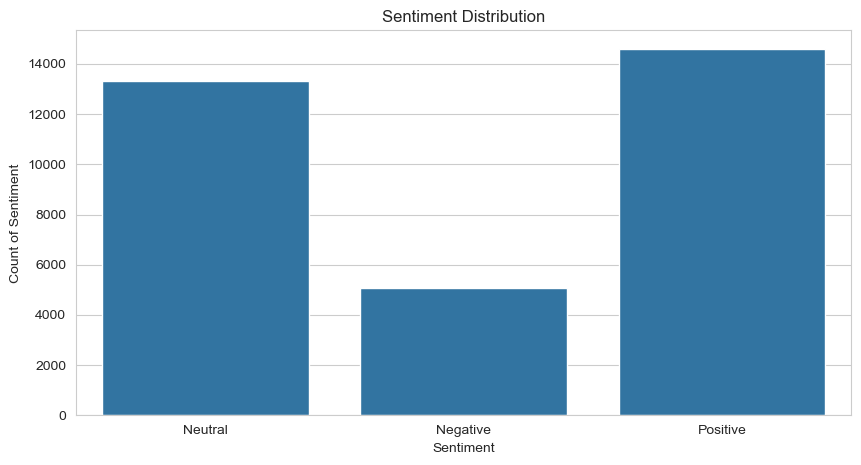

In [11]:
sns.set_style('whitegrid')
plt.figure(figsize=(10,5))

sns.countplot(x = 'Sentiment' , data = df)
plt.xlabel('Sentiment')
plt.ylabel('Count of Sentiment')
plt.title('Sentiment Distribution')
plt.show()